In [8]:
import matplotlib.pyplot as plt
import pandas as pd
from pandas.plotting import parallel_coordinates
import seaborn as sns
import numpy as np

# df_PT

In [9]:
Student_dropout = pd.read_csv('data/data.csv', sep=';')

In [10]:
Student_dropout.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

In [11]:
Student_dropout['Target'] = Student_dropout['Target'].replace('Graduate', 0).replace('Enrolled', 0).replace('Dropout', 1)

C:\Users\gusta\AppData\Local\Temp\ipykernel_18408\398414641.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  Student_dropout['Target'] = Student_dropout['Target'].replace('Graduate', 0).replace('Enrolled', 0).replace('Dropout', 1)


### Variáveis
- Todas as variáveis estão oficialmente em int ou float, garantindo que consiguimos comparar eles de maneira numérica

In [12]:
binary = [
    'Gender',
    'Displaced',
    'Scolarship Holder',
    'Educational special needs',
    'Debtor',
    'Tuition fees up to date'
]

Continuous= [
    'Admission grade',
    'Unemployment rate',
    'Inflation rate',
    'GDP'
]

In [13]:
drop = [col for col in Student_dropout.columns if col.startswith('Curricular units 2nd sem') and col != 'Curricular units 2nd sem (without evaluations)'] + ['Father\'s occupation', 'International']
Student_dropout.drop(columns=drop, inplace=True)

# Coding
Now that we cleaned our database and treated any thing that could cause trouble, it's time we start coding

In [14]:
from imblearn.over_sampling import RandomOverSampler
def oversampling(X, y):
    sampler = RandomOverSampler(random_state=42)
    X_resampled, y_resampled = sampler.fit_resample(X, y)
    return X_resampled, y_resampled

In [15]:
import sklearn.model_selection

y = Student_dropout['Target']
X = Student_dropout.drop(columns=['Target'])

X_train, X_test, y_train, y_test = sklearn.model_selection.train_test_split(X, y, test_size=0.2, random_state=42)
X_oversampled, y_oversampled = oversampling(X_train, y_train)

In [16]:
from numbers import Number

class Question():
    def __init__(self, column, value):
        self.column = column
        self.value = value
    
    def match(self, example):
        val = example[self.column]
        if isinstance(val, (Number, np.number)):
            return val >= self.value
        else:
            return val == self.value

    def __repr__(self):
        condition = "=="
        if isinstance(self.value, (int, float, np.number)):
            condition = ">="
        return f"Is {self.column} {condition} {str(self.value)}?"


In [17]:
def partition(rows, y, question):
    """
    Divide os dados de cada uma das linhas em duas listas,
    A primeira tem todos aqueles que respondem a pergunta;
    Já a segunda tem todos aqueles que não respondem a pergunta.
    """
    col_vals = rows[:, question.column]
    if isinstance(question.value, (Number, np.number)):
        mask = col_vals >= question.value
    else:
        mask = col_vals == question.value

    return (rows[mask], y[mask]), (rows[~mask], y[~mask])

def class_counts(y):  
    #Lista quantas vezes aparece na coluna de evasão os evadidos e não evadidos 
    counts = {}
    unique, cts = np.unique(y, return_counts=True)
    for label, c in zip(unique, cts):
        counts[int(label)] = int(c)
    return counts


def gini(y):
    if len(y) == 0:
        return 0.0
    _, counts = np.unique(y, return_counts=True)
    probs = counts / float(len(y))
    return 1.0 - np.sum(probs ** 2)

def info_gain(left_y, right_y, current_uncertainty):
    p = float(len(left_y)) / (len(left_y) + len(right_y))
    return current_uncertainty - p * gini(left_y) - (1 - p) * gini(right_y)
    
def find_best_split(rows, y, n_features, max_features=None):
    """
    Define a melhor pergunta para dividir os dados com base 
    no ganho de conhecimento (information gain) e no índice de Gini.
    """
    best_gain = 0
    best_question = None
    curr_gini = gini(y)
    total_cols = rows.shape[1] if n_features is None else min(n_features, rows.shape[1])

    if max_features is not None and max_features < total_cols:
        col_indices = np.random.choice(total_cols, size=max_features, replace=False)
    else:
        col_indices = range(total_cols)

    for col in col_indices:
        col_data = rows[:, col]
        unique_vals = np.unique(col_data)
        if len(unique_vals) > 25:
            values = np.unique(np.percentile(col_data, np.linspace(5, 95, 19)))
        else:
            values = unique_vals

        for val in values:
            question = Question(col, val)
            (_, true_labels), (_, false_labels) = partition(rows, y, question)

            if len(true_labels) > 0 and len(false_labels) > 0:
                gain = info_gain(true_labels, false_labels, curr_gini)
                if gain >= best_gain:
                    best_gain, best_question = gain, question

    return best_gain, best_question

In [18]:
from collections import Counter
class DecisionNode():
    #Tem filhos, é uma etapa de pergunta, e não uma folha da árvore de decisão.
    def __init__(self, question, true_branch, false_branch):
        self.question = question
        self.true_branch = true_branch
        self.false_branch = false_branch

    def predict(self, row):
        if isinstance(self, Leaf):
            return self.predictions
        if self.question.match(row):
            return self.true_branch.predict(row)
        else:
            return self.false_branch.predict(row)
        
    def predict_all(self, rows):
        return [self.predict(row) for row in rows]

class Leaf():
    #Não tem filhos, é a resposta final da árvore de decisão.
    def __init__(self, predictions):
        self.predictions = Counter(predictions).most_common(1)[0][0]

    def predict(self, row):
        return self.predictions

    def predict_all(self, rows):
        return [self.predictions for _ in rows]

In [19]:
class DecisionTree():
    def __init__(self, x, y, minSplit = 2, maxDepth = 5, n_features=29, max_features=None):
        self.x = x
        self.y = y
        self.minSplit = minSplit
        self.maxDepth = maxDepth
        self.n_features = n_features
        self.max_features = max_features
        
    def buildTree(self, curr_depth = 0):
        #Constrói a árvore de decisão recursivamente.
        n_samples = len(self.x)
        if n_samples < self.minSplit or curr_depth >= self.maxDepth or len(np.unique(self.y)) == 1:
            return Leaf(self.y)

        gain, question = find_best_split(self.x, self.y, self.n_features, self.max_features)

        if gain == 0 or question is None:
            return Leaf(self.y)
        (true_rows, true_labels), (false_rows, false_labels) = partition(self.x, self.y, question)


        if len(true_rows) == 0 or len(false_rows) == 0:
            return Leaf(self.y)
        
        curr_depth += 1
        true_branch = DecisionTree(true_rows, true_labels, self.minSplit, self.maxDepth, self.n_features, self.max_features).buildTree(curr_depth)
        false_branch = DecisionTree(false_rows, false_labels, self.minSplit, self.maxDepth, self.n_features, self.max_features).buildTree(curr_depth)

        return DecisionNode(question, true_branch, false_branch)

## ICRM

BEGIN
1. To initialise classifier
It creates two empty rule-set: one for dropout class and
another for success class.
2. To obtain the rules for predicting the dropout class
It runs GBGP algorithm in order to obtain a set of rules
that predicts the dropout class
3. To obtain the rules for predicting the success class
It runs GBGP algorithm in order to obtain a set of rules
that predicts the success class
4. To obtain the final rule-base classifier
It combines the rule-sets for the dropout and the success
classes to build the final classifier
  
END

In [11]:
class ICRM():
    """
    Classificador ICRM2 (Márquez-Vera et al., 2015):
    1. Cria dois conjuntos de regras vazios: dropout_rules (classe 1) e success_rules (classe 0)
    2. Executa o GBGP para obter regras que predizem a classe Dropout (1)
    3. Executa o GBGP para obter regras que predizem a classe Success (0)
    4. Combina ambos os conjuntos ponderados pelo Fitness (Se * Sp) para classificar novos alunos
    """
    def __init__(self, X, y, mutation_rate=0.2, crossover_rate=0.8,
                 population_size=20, generations=10, max_rules=5):
        self.X = X
        self.y = y
        self.mutation_rate = mutation_rate
        self.crossover_rate = crossover_rate
        self.population_size = population_size
        self.generations = generations
        self.max_rules = max_rules
        self.dropout_rules = []
        self.success_rules = []

    def build(self):
        # Passo 2: Regras para Dropout (classe 1)
        gbgp_dropout = GBGP(
            self.X, self.y, target_class=1,
            mutation_rate=self.mutation_rate, crossover_rate=self.crossover_rate,
            population_size=self.population_size, generations=self.generations,
            max_rules=self.max_rules
        )
        self.dropout_rules = gbgp_dropout.build()

        # Passo 3: Regras para Success/Continue (classe 0)
        gbgp_success = GBGP(
            self.X, self.y, target_class=0,
            mutation_rate=self.mutation_rate, crossover_rate=self.crossover_rate,
            population_size=self.population_size, generations=self.generations,
            max_rules=self.max_rules
        )
        self.success_rules = gbgp_success.build()
        return self

    def predict(self, row):
        # Passo 4: Combina os rule-sets de Dropout e Success pelo Fitness
        score_dropout = sum(fit for tree, fit, se, sp, cov in self.dropout_rules if tree.predict(row) == 1)
        score_success = sum(fit for tree, fit, se, sp, cov in self.success_rules if tree.predict(row) == 0)
        return 1 if score_dropout > score_success else 0

    def predict_all(self, rows):
        x_arr = rows.values if hasattr(rows, "values") else rows
        return [self.predict(row) for row in x_arr]

### GBGP

BEGIN  
    WHILE there are remaining instances and the number of
    rules is lower than the maximum allowed REPEAT  
    1.1. To initialise the population for a class  
    It generates the individuals (rules) of the population to
    learn a given class.  
    1.2. To do parent selection  
    It selects the parents on which the genetic operations are
    applied  
    1.3. To do crossover  
    It mixes the genetic information of the parents to
    generate an offspring  
    1.4. To do mutation  
    It mutates the offspring to facilitate the search
    exploration  
    1.5. To evaluate  
    It evaluates the fitness of the new rules  
    1.6. To update population  
    It selects the best rules from the parent population and
    the offspring to keep the population size constant with
    the best rules for the next generation  
    1.7. IF the algorithm has more generations to run  
    GOTO step 1.2 and iterate next generation  
    ELSE  
    CONTINUE with step 1.8  
    1.8. To select the best rule and append to the rule-set  
    It selects the best rule from the population using the
    fitness function and appends to the rule-set  
    1.9. To remove the instances covered by the rule  
    Instances covered by the rule are removed from the
    training examples so that new rules can be learned on the
    remaining instances  
    END WHILE  
    2. To return the rule-set  
END

In [12]:
import copy
import random
from sklearn.metrics import accuracy_score, classification_report

"""
This algorithm will be used on a DTL. 
So the parents are tree
each gene is one node
each node has a question and a prediction. 
We won't change the prediction, but we can change the question
question is a column and a value, we will focus on changing the value of the question, not the column
On the mutations, we can also change the tree depth.
"""

class GBGP():
    def __init__(self, X, y, target_class=1, mutation_rate=0.2, crossover_rate=0.8,
                 population_size=20, generations=10, max_rules=5, sample_size=600, max_depth=5):
        self.X = X.reset_index(drop=True)
        self.y = pd.Series(y).reset_index(drop=True)
        self.target_class = target_class
        self.mutation_rate = mutation_rate
        self.crossover_rate = crossover_rate
        self.population_size = population_size
        self.generations = generations
        self.max_rules = max_rules
        self.sample_size = sample_size
        self.max_depth = max_depth
        self.columns = list(X.columns)
        self.binary_cols = {i for i, col in enumerate(self.columns) if col in binary}
        self.continuous_cols = {i for i, col in enumerate(self.columns) if col in Continuous}

    def random_population(self, x_rem, y_rem):
        #Gera uma população aleatória de árvores de decisão, cada árvore é construída a partir de uma amostra balanceada dos dados.
        population = []
        pos_idx = np.where(y_rem == self.target_class)[0]
        neg_idx = np.where(y_rem != self.target_class)[0]
        half_k = self.sample_size // 2
        m_feat = max(4, int(np.sqrt(x_rem.shape[1])))

        for _ in range(self.population_size):
            p_sample = np.random.choice(pos_idx, size=min(half_k, len(pos_idx)), replace=True)
            n_sample = np.random.choice(neg_idx, size=min(half_k, len(neg_idx)), replace=True)
            indices = np.concatenate([p_sample, n_sample])
            depth = random.randint(3, self.max_depth)
            tree = DecisionTree(
                x_rem[indices], y_rem[indices],
                minSplit=2, maxDepth=depth,
                n_features=x_rem.shape[1], max_features=m_feat
            ).buildTree()
            population.append(tree)
        return population

    def select_parent(self, scored_pop):
        k = min(3, len(scored_pop))
        contenders = random.sample(scored_pop, k)
        contenders.sort(key=lambda item: item[1], reverse=True)
        return contenders[0][0]

    def crossover(self, parent1, parent2):
        child = copy.deepcopy(parent1)
        if isinstance(child, DecisionNode) and isinstance(parent2, DecisionNode):
            if random.random() < 0.5:
                child.true_branch = copy.deepcopy(parent2.true_branch)
            else:
                child.false_branch = copy.deepcopy(parent2.false_branch)
        return child

    def mutation(self, node, depth=0):
        #Muda o valor da pergunta do nó, ou muda a profundidade da árvore.
        if isinstance(node, Leaf):
            return node

        node = copy.deepcopy(node)
        if random.random() < self.mutation_rate:
            if random.random() < 0.9:
                col = node.question.column
                if col in self.binary_cols:
                    node.question.value = 1 - node.question.value
                elif col in self.continuous_cols:
                    col_values = self.X.iloc[:, col]
                    std_dev = col_values.std() * 0.1
                    node.question.value = float(node.question.value + random.gauss(0, std_dev))
                else:
                    candidates = [v for v in self.X.iloc[:, col].unique() if v != node.question.value]
                    if candidates:
                        node.question.value = random.choice(candidates)
            else:
                if isinstance(node.true_branch, DecisionNode):
                    node.true_branch = Leaf([self.target_class])
                elif isinstance(node.false_branch, DecisionNode):
                    node.false_branch = Leaf([1 - self.target_class])

        node.true_branch = self.mutation(node.true_branch, depth + 1)
        node.false_branch = self.mutation(node.false_branch, depth + 1)
        return node

    def test_individual(self, tree, x_eval, y_eval):
        # Avalia o indivíduo usando Fitness = Sensitivity * Specificity (Márquez-Vera et al., 2015)
        preds = np.array(tree.predict_all(x_eval))
        is_target = (y_eval == self.target_class)
        pred_target = (preds == self.target_class)

        tp = np.sum(pred_target & is_target)
        fn = np.sum((~pred_target) & is_target)
        tn = np.sum((~pred_target) & (~is_target))
        fp = np.sum(pred_target & (~is_target))

        sensitivity = tp / float(tp + fn) if (tp + fn) > 0 else 0.0
        specificity = tn / float(tn + fp) if (tn + fp) > 0 else 0.0
        fitness = sensitivity * specificity
        coverage = float(np.mean(pred_target))
        return fitness, sensitivity, specificity, coverage

    def build(self):
        rule_set = []
        x_full = self.X.values
        y_full = self.y.values
        x_rem = x_full.copy()
        y_rem = y_full.copy()

        while np.sum(y_rem == self.target_class) > 20 and len(rule_set) < self.max_rules:
            population = self.random_population(x_rem, y_rem)
            scored_pop = [(ind, *self.test_individual(ind, x_rem, y_rem)) for ind in population]

            for _ in range(self.generations):
                offspring = []
                while len(offspring) < self.population_size:
                    p1 = self.select_parent(scored_pop)
                    p2 = self.select_parent(scored_pop)

                    if random.random() < self.crossover_rate:
                        child = self.crossover(p1, p2)
                    else:
                        child = copy.deepcopy(p1)

                    child = self.mutation(child)
                    offspring.append(child)

                scored_offspring = [(ind, *self.test_individual(ind, x_rem, y_rem)) for ind in offspring]
                combined = scored_pop + scored_offspring
                combined.sort(key=lambda item: item[1], reverse=True)
                scored_pop = combined[:self.population_size]

            best_tree = scored_pop[0][0]
            global_fit, global_se, global_sp, global_cov = self.test_individual(best_tree, x_full, y_full)
            if global_fit <= 0:
                break
            rule_set.append((best_tree, global_fit, global_se, global_sp, global_cov))

            preds = np.array(best_tree.predict_all(x_rem))
            covered_target = (preds == self.target_class) & (y_rem == self.target_class)
            if np.sum(covered_target) == 0:
                break
            keep_mask = ~covered_target
            x_rem = x_rem[keep_mask]
            y_rem = y_rem[keep_mask]

        return rule_set

In [13]:
random.seed(42)
np.random.seed(42)
myICRM = ICRM(X_train, y_train)
myICRM.build()
myICRMPredictions = myICRM.predict_all(X_test.values)

random.seed(42)
np.random.seed(42)
myOverICRM = ICRM(X_oversampled, y_oversampled)
myOverICRM.build()
myOverICRMPredictions = myOverICRM.predict_all(X_test.values)

In [14]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(max_depth=5, random_state=42)
tree.fit(X_train, y_train)
treePredictions = tree.predict(X_test)

overTree = DecisionTreeClassifier(max_depth=5, random_state=42)
overTree.fit(X_oversampled, y_oversampled)
overTreePredictions = overTree.predict(X_test)

# Comparação dos resultados

Acurácia da Árvore de Decisão (SKLearn) Normal:
0.8112994350282486
Matriz de Confusão da Árvore de Decisão (SKLearn) Normal:


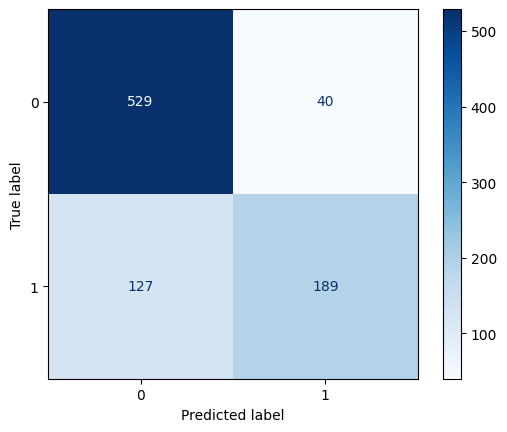

------------------------------------




Acurácia da Árvore de Decisão (SKLearn) com Dados Oversampled:
0.807909604519774
Matriz de Confusão da Árvore de Decisão (SKLearn) com Dados Oversampled:


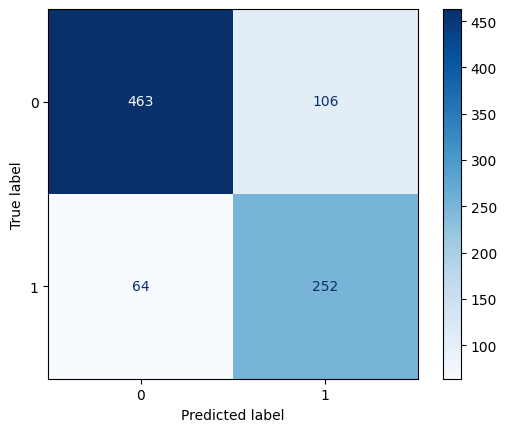

------------------------------------




Acurácia do ICRM Implementado:
0.8022598870056498
Matriz de Confusão do ICRM Implementado:


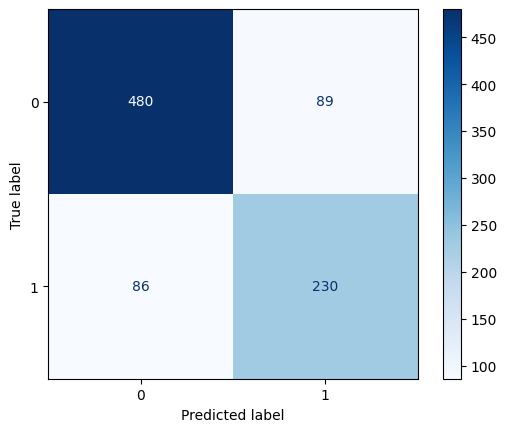

------------------------------------




Acurácia do ICRM Implementado com Dados Oversampled:
0.8011299435028248
Matriz de Confusão do ICRM Implementado com Dados Oversampled:


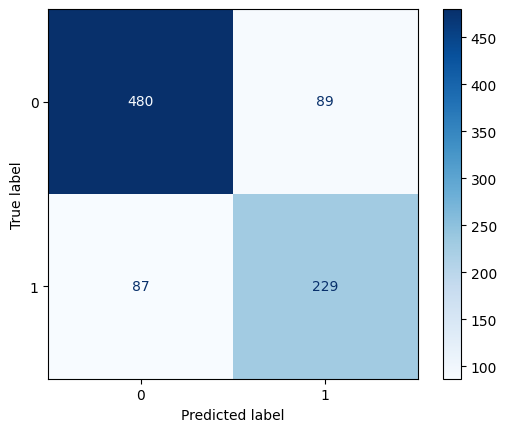

------------------------------------




In [15]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# ----------------------------------- #
# =========== Acurácia ============== #
# ----------------------------------- #


print("Acurácia da Árvore de Decisão (SKLearn) Normal:")
print(accuracy_score(y_test, treePredictions))
print("Matriz de Confusão da Árvore de Decisão (SKLearn) Normal:")
cm = confusion_matrix(y_test, treePredictions)
disp=ConfusionMatrixDisplay(cm)
disp.plot(cmap=plt.cm.Blues)
plt.show()
print("------------------------------------")
print("\n")

print("Acurácia da Árvore de Decisão (SKLearn) com Dados Oversampled:")
print(accuracy_score(y_test, overTreePredictions))
print("Matriz de Confusão da Árvore de Decisão (SKLearn) com Dados Oversampled:")
cm = confusion_matrix(y_test, overTreePredictions)
disp=ConfusionMatrixDisplay(cm)
disp.plot(cmap=plt.cm.Blues)
plt.show()
print("------------------------------------")
print("\n")

print("Acurácia do ICRM Implementado:")
print(accuracy_score(y_test, myICRMPredictions))
print("Matriz de Confusão do ICRM Implementado:")
cm = confusion_matrix(y_test, myICRMPredictions)
disp=ConfusionMatrixDisplay(cm)
disp.plot(cmap=plt.cm.Blues)
plt.show()
print("------------------------------------")
print("\n")

print("Acurácia do ICRM Implementado com Dados Oversampled:")
print(accuracy_score(y_test, myOverICRMPredictions))
print("Matriz de Confusão do ICRM Implementado com Dados Oversampled:")
cm = confusion_matrix(y_test, myOverICRMPredictions)
disp=ConfusionMatrixDisplay(cm)
disp.plot(cmap=plt.cm.Blues)
plt.show()
print("------------------------------------")
print("\n")